# HW2 Part 1: Data Cleaning & Validation

**Goal:** turn the intentionally dirty `ohlc_hw` table into a trustworthy `ohlc_hw_cleaned` table that the risk reports can use.

The notebook follows one rule throughout: **diagnose first, repair second, validate last.** Every repair is recorded as a flag column, and any row I cannot defend repairing goes to a quarantine table with a reason. Nothing is silently dropped.

| Step | Section |
|---|---|
| Load & inspect | 1.1 |
| Detect issues → Data Quality Report | 1.2 |
| Investigate the 3σ outliers | 1.2 (outliers) |
| Clean (with injected examples for cases absent from the data) | 1.3 |
| Validate, account for every row, save | 1.3 (validation) |

**Run order:** this notebook runs first. It reads `data/data.db` relative to this folder (a local copy of the bCourses database, which is gitignored) and writes the cleaned table back into that same local copy. The raw `ohlc_hw` table is never modified.

In [1]:
import hashlib
import sqlite3
from contextlib import closing
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

DB_PATH = Path('data/data.db')          # local working copy; never committed
RAW_TABLE = 'ohlc_hw'                   # dirty input (read only)
REF_TABLE = 'ohlc'                      # course reference table (read only)
CLEAN_TABLE = 'ohlc_hw_cleaned'         # output
QUARANTINE_TABLE = 'ohlc_hw_quarantine'
REPORT_TABLE = 'ohlc_hw_quality_report'
LABEL_AUDIT_TABLE = 'ohlc_hw_ticker_audit'

RAW_PRICES = ['open', 'high', 'low', 'close']
ALL_PRICES = RAW_PRICES + ['adj_close']
KEY = ['ticker', 'ts']

if not DB_PATH.is_file():
    raise FileNotFoundError(f'Copy the bCourses database to {DB_PATH.resolve()} before running.')

## 1.1 Load and inspect the data

In [2]:
def load_table(table: str) -> pd.DataFrame:
    # Read a whole table from the local database (read-only connection).
    with closing(sqlite3.connect(DB_PATH.resolve().as_uri() + '?mode=ro', uri=True)) as conn:
        return pd.read_sql_query(f'SELECT * FROM {table}', conn)


def table_fingerprint(df: pd.DataFrame) -> str:
    # Hash of the table contents, used later to prove the raw table was not modified.
    return hashlib.sha256(pd.util.hash_pandas_object(df, index=False).values.tobytes()).hexdigest()


raw = load_table(RAW_TABLE)
ref = load_table(REF_TABLE)
raw_fingerprint = table_fingerprint(raw)

raw.info()
display(raw.describe().T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397711 entries, 0 to 397710
Data columns (total 8 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   ts         397711 non-null  object 
 1   open       397711 non-null  float64
 2   high       397711 non-null  float64
 3   low        397711 non-null  float64
 4   close      397711 non-null  float64
 5   adj_close  377856 non-null  float64
 6   volume     397711 non-null  int64  
 7   ticker     397711 non-null  object 
dtypes: float64(5), int64(1), object(2)
memory usage: 24.3+ MB


,count,mean,std,min,25%,50%,75%,max
open,397711.0,4.628548e+01,6.713259e+01,0.000000,4.209938e+00,19.85,57.53,6.042600e+02
high,397711.0,4.674766e+01,6.777821e+01,0.005208,4.240000e+00,20.06,58.13,6.086300e+02
low,397711.0,4.581628e+01,6.647718e+01,0.004801,4.160000e+00,19.63,56.95,5.978800e+02
close,397711.0,4.629290e+01,6.714188e+01,0.005208,4.200000e+00,19.86,57.53,6.054000e+02
adj_close,377856.0,5.165225e+01,1.945840e+02,0.002945,1.390000e+00,11.96,43.77,1.044251e+04
volume,397711.0,3.097773e+07,1.266237e+08,0.000000,1.730700e+06,4648200.00,11023796.50,9.276606e+09


**Columns**

| Column | Meaning |
|---|---|
| `ts` | observation (trading) date, stored as text |
| `ticker` | stock symbol (dirty: contains HTML markup, see below) |
| `open`, `high`, `low`, `close` | raw daily prices. They must satisfy `low ≤ open, close ≤ high` |
| `adj_close` | vendor close adjusted for splits and dividends (backward adjusted, so `adj_close ≤ close`) |
| `volume` | shares traded that day |

`describe()` already shows problems: `adj_close` has fewer non-null values than the other columns, its maximum (≈ 10,442) is far above the maximum raw close (≈ 605), and `open` has a minimum of 0.

In [3]:
print(f"Rows: {len(raw):,}")
print(f"Date range: {raw['ts'].min()} to {raw['ts'].max()}")
print(f"Distinct raw ticker labels: {raw['ticker'].nunique()}")
print('Example labels:')
for label in raw['ticker'].drop_duplicates().head(6):
    print('   ', repr(label))

Rows: 397,711
Date range: 1962-01-02 to 2024-12-06
Distinct raw ticker labels: 150
Example labels:
    'CAT'
    'CVX'
    'HD'
    'AAPL'
    'TRV'
    'JNJ'


There are 150 distinct labels, but they are HTML-decorated versions of the same symbols. I normalize them first (strip tags, trim whitespace, upper-case) **before** any grouping or deduplication, and keep the original label in `raw_ticker` plus a separate label audit table.

In [4]:
def normalize_ticker_labels(labels: pd.Series) -> pd.Series:
    # Strip HTML tags, surrounding whitespace, and case differences from ticker labels.
    return labels.str.replace(r'<[^>]*>', '', regex=True).str.strip().str.upper()


def normalize(df: pd.DataFrame) -> pd.DataFrame:
    # Normalized ticker plus the original label; parse ts into real dates.
    out = df.rename(columns={'ticker': 'raw_ticker'})
    out['ticker'] = normalize_ticker_labels(out['raw_ticker'])
    out['ts'] = pd.to_datetime(out['ts'], format='%Y-%m-%d', errors='coerce')  # bad dates become NaT
    return out


data = normalize(raw)
ref_norm = normalize(ref)   # the reference table is already clean; this only parses its dates

label_audit = (data.groupby(['ticker', 'raw_ticker']).size().rename('rows').reset_index())
print(f"Normalized tickers ({data['ticker'].nunique()}):", sorted(data['ticker'].unique()))
print('Unparseable dates:', data['ts'].isna().sum())
display(label_audit[label_audit['ticker'] == 'AAPL'])

per_ticker = data.groupby('ticker')['ts'].agg(first_date='min', last_date='max', raw_rows='size')
per_ticker[['first_date', 'last_date']] = per_ticker[['first_date', 'last_date']].apply(lambda c: c.dt.date)
display(per_ticker.T)

Normalized tickers (30): ['AAPL', 'AMGN', 'AMZN', 'AXP', 'BA', 'CAT', 'CRM', 'CSCO', 'CVX', 'DIS', 'GS', 'HD', 'HON', 'IBM', 'JNJ', 'JPM', 'KO', 'MCD', 'MMM', 'MRK', 'MSFT', 'NKE', 'NVDA', 'PG', 'SHW', 'TRV', 'UNH', 'V', 'VZ', 'WMT']
Unparseable dates: 0


,ticker,raw_ticker,rows
0,AAPL,"<a target=""_blank""><span style=""color: blue"">A...",307
1,AAPL,"<a target=""_blank""><span style=""color: red"">AA...",318
2,AAPL,"<a target=""_blank""><span style=""font-weight: b...",306
3,AAPL,"<a target=""_blank""><span style=""font-weight: b...",264
4,AAPL,AAPL,10747


ticker,AAPL,AMGN,AMZN,AXP,BA,CAT,CRM,CSCO,CVX,DIS,GS,HD,HON,IBM,JNJ,JPM,KO,MCD,MMM,MRK,MSFT,NKE,NVDA,PG,SHW,TRV,UNH,V,VZ,WMT
first_date,1980-12-12,1983-06-17,1997-05-15,1972-04-03,1962-01-02,1962-01-02,2004-06-23,1990-02-16,1962-01-02,1962-01-02,1999-05-04,1981-09-22,1962-01-02,1962-01-02,1962-01-02,1969-03-05,1962-01-02,1966-07-05,1962-01-02,1962-01-02,1986-03-13,1980-12-02,1999-01-22,1962-01-02,1968-01-02,1972-04-03,1984-10-17,2008-03-19,1983-11-21,1972-04-03
last_date,2024-10-18,2024-10-18,2024-12-06,2024-10-18,2024-10-18,2024-10-18,2024-10-18,2024-10-18,2024-12-06,2024-12-06,2024-10-18,2024-10-18,2024-10-18,2024-12-06,2024-10-18,2024-10-18,2024-12-06,2024-10-18,2024-10-18,2024-12-06,2024-10-18,2024-12-06,2024-10-18,2024-12-06,2024-10-18,2024-10-18,2024-10-18,2024-10-18,2024-10-18,2024-10-18
raw_rows,11942,11290,7458,14260,16980,17044,5525,9427,17073,17151,6931,11731,17111,17138,17097,15145,17147,15830,17041,17111,10486,11989,7030,17108,15470,14325,10909,4516,11151,14295


Note that histories have **different end dates**: most tickers end on 2024-10-18, while AMZN, CVX, DIS, IBM, KO, MRK, NKE, and PG run to 2024-12-06. That matters for Part 3.

## 1.2 Detect data quality issues

All detectors are plain functions that return flags. They do **not** modify the data, so the diagnosis is kept separately from the repairs.

### Duplicates and conflicting keys

In [5]:
DATA_COLS = ['ticker', 'ts', 'open', 'high', 'low', 'close', 'adj_close', 'volume']


def drop_exact_duplicates(df: pd.DataFrame) -> pd.DataFrame:
    # Keep one copy of each fully identical record (after ticker normalization).
    # `n_copies` records how many identical rows were collapsed, so nothing is lost silently.
    counts = df.groupby(DATA_COLS, dropna=False, sort=False).size().rename('n_copies').reset_index()
    first = df.drop_duplicates(DATA_COLS, keep='first')
    return first.merge(counts, on=DATA_COLS, how='left')


def find_conflicting_keys(df: pd.DataFrame) -> pd.DataFrame:
    # Rows that share (ticker, ts) but disagree in at least one value.
    return df[df.duplicated(KEY, keep=False)].sort_values(KEY)


dedup = drop_exact_duplicates(data)
conflicts = find_conflicting_keys(dedup)
print(f"Exact duplicate rows removed: {len(data) - len(dedup):,}")
print(f"Rows after exact deduplication: {len(dedup):,}")
print(f"Rows in conflicting (ticker, ts) keys: {len(conflicts)}")

Exact duplicate rows removed: 29,460
Rows after exact deduplication: 368,251
Rows in conflicting (ticker, ts) keys: 0


Every repeated `(ticker, ts)` key is an exact copy, so there are no conflicting keys to investigate in this database. The detector is still part of the pipeline, and I test it on an injected example below.

### Missing values

In [6]:
def detect_missing_values(df: pd.DataFrame) -> pd.DataFrame:
    # Count missing (NaN) and non-finite (±inf) cells per numeric column.
    numeric = df[ALL_PRICES + ['volume']].astype(float)
    return pd.DataFrame({'missing': numeric.isna().sum(),
                         'infinite': np.isinf(numeric).sum()})


display(detect_missing_values(dedup))

,missing,infinite
open,0,0
high,0,0
low,0,0
close,0,0
adj_close,18374,0
volume,0,0


Only `adj_close` has missing cells. Raw prices and volume are complete.

### Missing trading days

**Reference calendar:** for each ticker I use the dates of the same ticker in the supplied `ohlc` table, restricted to that ticker's own first-to-last date in `ohlc_hw`. Business weekdays would wrongly count exchange holidays as gaps. A missing *day* (absent row) is a different check from a missing *cell*. I only detect absent rows here. I do not invent prices for them.

In [7]:
def detect_missing_trading_days(df: pd.DataFrame, calendar: pd.DataFrame) -> pd.DataFrame:
    # Return (ticker, ts) pairs present in the reference calendar but absent from df,
    # within each ticker's own observed history [first date, last date].
    span = df.groupby('ticker')['ts'].agg(first='min', last='max')
    cal = calendar[KEY].drop_duplicates().merge(span, left_on='ticker', right_index=True)
    cal = cal[(cal['ts'] >= cal['first']) & (cal['ts'] <= cal['last'])]
    merged = cal[KEY].merge(df[KEY].drop_duplicates(), on=KEY, how='left', indicator=True)
    return merged.loc[merged['_merge'] == 'left_only', KEY].reset_index(drop=True)


def summarize_missing_days(df: pd.DataFrame, missing: pd.DataFrame) -> list[str]:
    # One sentence per ticker, including tickers with zero gaps.
    span = df.groupby('ticker')['ts'].agg(['min', 'max'])
    counts = missing.groupby('ticker').size()
    return [f"Ticker {t} is missing {int(counts.get(t, 0))} trading days between "
            f"{row['min']:%Y-%m-%d} and {row['max']:%Y-%m-%d}" for t, row in span.iterrows()]


# Demonstration on a tiny example with one deliberately removed date.
demo_calendar = pd.DataFrame({'ticker': 'DEMO',
                              'ts': pd.to_datetime(['2024-01-02', '2024-01-03', '2024-01-04', '2024-01-05'])})
demo_obs = demo_calendar.drop(index=2)  # remove 2024-01-04
demo_missing = detect_missing_trading_days(demo_obs, demo_calendar)
display(demo_missing)
print(summarize_missing_days(demo_obs, demo_missing)[0])
assert demo_missing['ts'].tolist() == [pd.Timestamp('2024-01-04')]

,ticker,ts
0,DEMO,2024-01-04


Ticker DEMO is missing 1 trading days between 2024-01-02 and 2024-01-05


In [8]:
missing_days = detect_missing_trading_days(dedup, ref_norm)
for line in summarize_missing_days(dedup, missing_days)[:5]:
    print(line)
print('...')
print(f"Total missing trading days across all tickers: {len(missing_days)}")

Ticker AAPL is missing 0 trading days between 1980-12-12 and 2024-10-18
Ticker AMGN is missing 0 trading days between 1983-06-17 and 2024-10-18
Ticker AMZN is missing 0 trading days between 1997-05-15 and 2024-12-06
Ticker AXP is missing 0 trading days between 1972-04-03 and 2024-10-18
Ticker BA is missing 0 trading days between 1962-01-02 and 2024-10-18
...
Total missing trading days across all tickers: 0


The detector finds **zero** missing trading days. After deduplication every ticker has exactly the reference dates. This is a valid result, so I report zero rather than inventing gaps.

### Calendar oddity: weekend dates

In [9]:
weekend = dedup['ts'].dt.dayofweek >= 5
print(f"Rows dated on a weekend: {weekend.sum()}")
display(dedup.loc[weekend].groupby(dedup.loc[weekend, 'ts'].dt.year).size().rename('rows'))
print('Also present in the reference table:',
      int((ref_norm['ts'].dt.dayofweek >= 5).sum()), 'rows')

Rows dated on a weekend: 384


ts
1974    240
1975    144
Name: rows, dtype: int64

Also present in the reference table: 384 rows


384 rows from 1974–1975 are dated on Sundays, for all tickers at once, in both `ohlc_hw` and the reference. This looks like a vendor timestamp convention for that period, not a corrupted value. I **keep** these rows and add a `low` severity flag.

### Outliers: 3σ return screen

In [10]:
def detect_return_outliers(df: pd.DataFrame, price_col: str = 'close', n_std: float = 3.0) -> pd.DataFrame:
    # Simple daily returns (close - prev_close) / prev_close within each ticker, sorted by date.
    # Flag |return - mean| > n_std * std (sample std, ddof=1), both tails.
    # Undefined returns (first row, non-finite) are excluded; a ticker whose std is 0 or
    # undefined gets z = NaN and is never flagged (there is no dispersion to compare to).
    d = df.sort_values(KEY)[KEY + [price_col]].copy()
    d['ret'] = d.groupby('ticker')[price_col].pct_change(fill_method=None)
    d.loc[~np.isfinite(d['ret']), 'ret'] = np.nan
    grouped = d.groupby('ticker')['ret']
    d['mean_ret'] = grouped.transform('mean')
    d['std_ret'] = grouped.transform(lambda s: s.std(ddof=1))
    usable = np.isfinite(d['std_ret']) & (d['std_ret'] > 0)
    d['z'] = np.where(usable, (d['ret'] - d['mean_ret']) / d['std_ret'], np.nan)
    d['is_outlier'] = d['z'].abs() > n_std   # NaN compares False
    return d


raw_outliers = detect_return_outliers(dedup, 'close')
print(f"Raw-close return outliers flagged: {raw_outliers['is_outlier'].sum():,} "
      f"of {raw_outliers['ret'].notna().sum():,} defined returns")
print('Tickers with zero/undefined std:', int((~np.isfinite(raw_outliers.groupby('ticker')['std_ret'].first())
                                                 | (raw_outliers.groupby('ticker')['std_ret'].first() == 0)).sum()))
display(raw_outliers.loc[raw_outliers['is_outlier']].groupby('ticker').size().describe().to_frame('outliers per ticker').T)

Raw-close return outliers flagged: 5,056 of 368,221 defined returns
Tickers with zero/undefined std: 0


,count,mean,std,min,25%,50%,75%,max
outliers per ticker,30.0,168.533333,48.088807,67.0,144.0,179.0,208.5,228.0


### Price inconsistencies and nonpositive values

In [11]:
def detect_price_inconsistencies(df: pd.DataFrame) -> pd.DataFrame:
    # Boolean flag per check; one row of flags per observation (several can be True at once).
    # Raw OHLC bounds do not apply to adj_close, which is checked only for positivity/finiteness.
    raw_px = df[RAW_PRICES].astype(float)
    adj = df['adj_close'].astype(float)
    vol = df['volume'].astype(float)
    return pd.DataFrame({
        'high_below_close': df['high'] < df['close'],
        'low_above_close': df['low'] > df['close'],
        'open_outside_range': (df['open'] < df['low']) | (df['open'] > df['high']),
        'high_below_low': df['high'] < df['low'],
        'nonpositive_raw_price': raw_px.le(0).any(axis=1),
        'nonfinite_raw_price': np.isinf(raw_px).any(axis=1),
        'missing_raw_price': raw_px.isna().any(axis=1),
        'nonpositive_or_nonfinite_adj_close': adj.le(0) | np.isinf(adj),
        'zero_volume': vol.eq(0),
        'invalid_volume': vol.isna() | np.isinf(vol) | vol.lt(0),
    }, index=df.index)


price_flags = detect_price_inconsistencies(dedup)
display(price_flags.sum().to_frame('rows flagged'))
display(dedup.loc[price_flags['nonpositive_raw_price'], DATA_COLS])

,rows flagged
high_below_close,0
low_above_close,0
open_outside_range,5
high_below_low,0
nonpositive_raw_price,5
nonfinite_raw_price,0
missing_raw_price,0
nonpositive_or_nonfinite_adj_close,0
zero_volume,75
invalid_volume,0


,ticker,ts,open,high,low,close,adj_close,volume
97792,PG,1962-01-02,0.0,1.44000,1.42000,1.43000,0.259300,192000
215385,MCD,1966-07-05,0.0,0.27366,0.26749,0.26955,0.118090,388800
271962,CVX,1962-01-02,0.0,3.30000,3.24000,3.30000,0.335750,105840
327908,JNJ,1962-01-02,0.0,0.22338,0.22222,0.22338,0.064012,0
339808,MRK,1962-01-02,0.0,0.39703,0.39317,0.39537,0.068447,633830


* No `high < close` or `low > close` violations exist in this database. The bounds repair is still implemented and demonstrated on injected rows in 1.3.
* Five rows have `open = 0`, which is impossible for an equity price. Each one is the **first** observation of its ticker (1962 or 1966). These are the only `open_outside_range` cases too, because 0 is below `low`.
* 75 zero-volume days. Most are in old data, and zero volume can mean stale or unreported data rather than no trading, so I flag them but keep them.

### Adjusted close
`adj_close` is missing on 18,374 rows, and `describe()` showed impossible magnitudes. I check it three ways:
1. missing / nonpositive / non-finite;
2. **convention check without any reference:** under backward adjustment, `adj_close / close ≤ 1`. A factor above 1 is impossible;
3. **reference check:** compare with the supplied `ohlc` table at the same `(ticker, ts)`. The raw OHLC and volume in `ohlc_hw` match `ohlc` exactly (verified below), so `ohlc` is a trusted source for the date-specific adjustment factor `adj_close / close`.

In [12]:
def attach_reference(df: pd.DataFrame, reference: pd.DataFrame) -> pd.DataFrame:
    # Add reference close/adj_close/volume (suffix _ref) and the trusted adjustment factor.
    cols = KEY + ['open', 'high', 'low', 'close', 'adj_close', 'volume']
    out = df.merge(reference[cols], on=KEY, how='left', suffixes=('', '_ref'))
    out['ref_factor'] = out['adj_close_ref'] / out['close_ref']
    return out


def detect_adj_close_issues(df: pd.DataFrame, rtol: float = 1e-6) -> pd.DataFrame:
    # df must already carry reference columns (see attach_reference).
    factor = df['adj_close'] / df['close']
    has_ref = df['adj_close_ref'].notna()
    return pd.DataFrame({
        'adj_missing': df['adj_close'].isna(),
        'adj_factor_above_one': factor > 1 + 1e-6,
        'adj_mismatch_reference': df['adj_close'].notna() & has_ref
                                  & ~np.isclose(df['adj_close'], df['adj_close_ref'], rtol=rtol),
        'no_reference_row': ~has_ref,
    }, index=df.index)


checked = attach_reference(dedup, ref_norm)
for col in ['open', 'high', 'low', 'close', 'volume']:
    same = np.isclose(checked[col], checked[f'{col}_ref'], rtol=1e-9, equal_nan=True).all()
    print(f"{col:>6} identical to reference: {same}")

adj_flags = detect_adj_close_issues(checked)
display(adj_flags.sum().to_frame('rows flagged'))
caught = (adj_flags['adj_mismatch_reference'] & adj_flags['adj_factor_above_one']).sum()
print(f"Reference mismatches also caught by the factor>1 rule alone: {caught:,} / {adj_flags['adj_mismatch_reference'].sum():,}")
ratio = (checked['adj_close'] / checked['adj_close_ref'])[adj_flags['adj_mismatch_reference']]
print(f"Corrupted adj_close is {ratio.min():.1f}x to {ratio.max():.1f}x the reference value")

  open identical to reference: True
  high identical to reference: True
   low identical to reference: True
 close identical to reference: True


volume identical to reference: True


,rows flagged
adj_missing,18374
adj_factor_above_one,10348
adj_mismatch_reference,10417
no_reference_row,0


Reference mismatches also caught by the factor>1 rule alone: 10,348 / 10,417
Corrupted adj_close is 4.0x to 24.0x the reference value


About 10,400 non-missing `adj_close` values are **4×–24× too large**. Nearly all of them already fail the "factor ≤ 1" convention, and the reference confirms every case. Together with the missing values, roughly 29k rows (8%) have a wrong adjusted close. Every return and drawdown in the report would be wrong without this repair.

### Investigating the 3σ outliers
A 3σ flag on raw close is a **review flag, not a deletion rule.** Over 60 years many flags are genuine (1987, 2008, March 2020). I classify every flagged day using evidence:

| Category | Evidence | Action |
|---|---|---|
| `adjustment_explained` | the trusted *adjusted* return on that day is **not** a 3σ outlier: the raw jump is absorbed by the split/dividend adjustment | keep (corporate action) |
| `confirmed_data_error` | (a) price jumps and the **next day fully reverts** (close₊₁ within 2% of close₋₁), (b) **zero volume** on the jump day, (c) the vendor's own adjustment factor on that day disagrees >5% with both neighbors, while the neighbors agree with each other. A real event would not trade zero shares, and a real price would not break the vendor's own adjustment series | interpolate from neighbors |
| `reversal_of_error` | the day right after a confirmed error (its return becomes normal after repair) | none needed |
| `unexplained_move` | none of the above. Most likely genuine market moves. I cannot attribute them to news without a news source, so I do not claim a cause | keep, flag for review |

In [13]:
def classify_outliers(df: pd.DataFrame, n_std: float = 3.0,
                      revert_tol: float = 0.02, factor_tol: float = 0.05) -> pd.DataFrame:
    # Classify raw-close 3σ outliers. df needs reference columns (attach_reference).
    d = df.sort_values(KEY).reset_index(drop=True)
    raw_scr = detect_return_outliers(d, 'close', n_std)
    adj_scr = detect_return_outliers(d.assign(trusted_adj=d['adj_close_ref']), 'trusted_adj', n_std)
    d['ret'] = raw_scr['ret'].values
    d['z'] = raw_scr['z'].values
    d['is_outlier'] = raw_scr['is_outlier'].values
    d['adj_is_outlier'] = adj_scr['is_outlier'].values

    g = d.groupby('ticker')
    prev_close, next_close = g['close'].shift(1), g['close'].shift(-1)
    prev_f, next_f = g['ref_factor'].shift(1), g['ref_factor'].shift(-1)
    reverts = (next_close / prev_close - 1).abs() < revert_tol
    neighbors_agree = (prev_f / next_f - 1).abs() < factor_tol
    factor_breaks = ((d['ref_factor'] / prev_f - 1).abs() > factor_tol) & ((d['ref_factor'] / next_f - 1).abs() > factor_tol)
    confirmed = d['is_outlier'] & reverts & d['volume'].eq(0) & neighbors_agree & factor_breaks

    d['outlier_category'] = None
    d.loc[d['is_outlier'], 'outlier_category'] = 'unexplained_move'
    d.loc[d['is_outlier'] & ~d['adj_is_outlier'], 'outlier_category'] = 'adjustment_explained'
    after_error = confirmed.groupby(d['ticker']).shift(1, fill_value=False).astype(bool)
    d.loc[d['is_outlier'] & after_error, 'outlier_category'] = 'reversal_of_error'
    d.loc[confirmed, 'outlier_category'] = 'confirmed_data_error'
    return d


diag = classify_outliers(checked)
display(diag['outlier_category'].value_counts().to_frame('days'))
confirmed_errors = diag.loc[diag['outlier_category'] == 'confirmed_data_error', KEY]
display(confirmed_errors)

,days
outlier_category,
unexplained_move,4844
adjustment_explained,206
confirmed_data_error,3
reversal_of_error,3


,ticker,ts
318332,TRV,1976-10-28
318873,TRV,1978-12-20
319538,TRV,1981-08-10


In [14]:
# Evidence for the confirmed errors: the day before, the error day, and the day after.
cols = ['ticker', 'ts', 'open', 'high', 'low', 'close', 'volume', 'adj_close_ref', 'ref_factor', 'ret', 'outlier_category']
for _, row in confirmed_errors.iterrows():
    window = diag[(diag['ticker'] == row['ticker'])]
    i = window.index[window['ts'] == row['ts']][0]
    display(diag.loc[i - 1:i + 1, cols])

,ticker,ts,open,high,low,close,volume,adj_close_ref,ref_factor,ret,outlier_category
318331,TRV,1976-10-27,4.61,4.61,4.61,4.61,230400,0.98046,0.212681,0.024444,None
318332,TRV,1976-10-28,9.22,9.22,9.22,9.22,0,3.21000,0.348156,1.000000,confirmed_data_error
318333,TRV,1976-10-29,4.69,4.69,4.69,4.69,79200,0.99707,0.212595,-0.491323,reversal_of_error


,ticker,ts,open,high,low,close,volume,adj_close_ref,ref_factor,ret,outlier_category
318872,TRV,1978-12-19,4.02,4.02,4.02,4.02,72000,0.90645,0.225485,0.000000,None
318873,TRV,1978-12-20,8.03,8.03,8.03,8.03,0,2.80000,0.348692,0.997512,confirmed_data_error
318874,TRV,1978-12-21,4.09,4.09,4.09,4.09,105600,0.92409,0.225939,-0.490660,reversal_of_error


,ticker,ts,open,high,low,close,volume,adj_close_ref,ref_factor,ret,outlier_category
319537,TRV,1981-08-07,6.03,6.03,6.03,6.03,264800,1.57,0.260365,-0.00495,None
319538,TRV,1981-08-10,12.06,12.06,12.06,12.06,0,4.20,0.348259,1.00000,confirmed_data_error
319539,TRV,1981-08-11,6.03,6.03,6.03,6.03,24800,1.57,0.260365,-0.50000,reversal_of_error


The three TRV days (1976-10-28, 1978-12-20, 1981-08-10) show the close **exactly doubling** for one day, with zero volume, then returning to the old level. The vendor's own adjusted factor also breaks on those days. These are recording errors, so I interpolate them (1.3).

Examples of other categories:
* **AAPL 2000-09-29 (−52%)**: the adjusted series drops by the same amount, the day traded about 3.1B shares (several times normal), and the price stayed down. That fits a genuine market move (Apple warned on earnings that week, though I have no news feed in this dataset to confirm the cause). Kept and flagged `unexplained_move`.
* **AXP 1972-12-14 (−13%, zero volume, next day reverts)**: suspicious, but the vendor adjustment factor is consistent with its neighbors. That is not enough evidence for a confirmed error, so I keep it and flag it for review rather than inventing a repair.
* **MCD 1968-01-02 (−75%)**: the raw and adjusted prices both fall by 75% and **stay** there, with very high volume. That pattern looks like a 4-for-1 split the vendor did not adjust for, but I cannot verify a 1968 corporate action from this data. It is kept and flagged as `unexplained_move` with this uncertainty stated. It is far outside any report window used in Parts 2–3.

In [15]:
diag.loc[(diag['ticker'] == 'AXP') & (diag['ts'].between('1972-12-12', '1972-12-18')), cols]

,ticker,ts,open,high,low,close,volume,adj_close_ref,ref_factor,ret,outlier_category
28584,AXP,1972-12-12,4.63,4.63,4.63,4.63,672324,1.56,0.336933,-0.006438,None
28585,AXP,1972-12-13,4.59,4.59,4.59,4.59,844816,1.55,0.337691,-0.008639,None
28586,AXP,1972-12-14,4.01,4.01,4.01,4.01,0,1.35,0.336658,-0.126362,unexplained_move
28587,AXP,1972-12-15,4.60,4.60,4.60,4.60,979282,1.56,0.339130,0.147132,unexplained_move
28588,AXP,1972-12-18,4.60,4.60,4.60,4.60,421049,1.56,0.339130,0.000000,None


### Data Quality Report
One row per issue per observation (an observation can appear several times). Ticker-label markup is reported once per raw label, with the number of affected rows, instead of 40k repetitive rows.

**Severity choices**
* **high**: the value would directly corrupt the prices/returns used in the reports: wrong or missing `adj_close`, impossible OHLC relationships, nonpositive/non-finite prices, confirmed spike errors, conflicting keys.
* **medium**: a real risk that needs review but is not automatically wrong: unexplained 3σ moves (often genuine), exact duplicate records (they would double-count days if not removed), missing trading days.
* **low**: cosmetic or informational issues: ticker markup (fixed deterministically), zero volume (possible stale data, does not affect prices), weekend dates (vendor convention), and outliers explained by the adjustment.

In [16]:
REPORT_COLS = ['ticker', 'issue_type', 'issue_date', 'description', 'severity']


def issue_rows(frame: pd.DataFrame, mask: pd.Series, issue_type: str, severity: str, description) -> pd.DataFrame:
    # Build report rows for the observations selected by mask. description may be a string
    # or a function of the selected rows returning a Series of strings.
    sub = frame.loc[mask]
    text = description(sub) if callable(description) else description
    return pd.DataFrame({'ticker': sub['ticker'].values, 'issue_type': issue_type,
                         'issue_date': sub['ts'].values,
                         'description': np.asarray(text, dtype=object) if callable(description) else text,
                         'severity': severity})


def fmt(series: pd.Series, digits: int = 4) -> pd.Series:
    return series.round(digits).astype(str)


def build_quality_report(data, dedup, checked, diag, missing_days, conflicts, label_audit) -> pd.DataFrame:
    parts = []
    # Ticker markup: one row per raw label that needed normalization.
    dirty_labels = label_audit[label_audit['raw_ticker'] != label_audit['ticker']]
    parts.append(pd.DataFrame({
        'ticker': dirty_labels['ticker'], 'issue_type': 'ticker_markup', 'issue_date': pd.NaT,
        'description': dirty_labels['rows'].astype(str) + " rows labelled " + dirty_labels['raw_ticker'].map(repr)
                       + " normalized to " + dirty_labels['ticker'],
        'severity': 'low'}))
    # Exact duplicates: one row per duplicated record.
    parts.append(issue_rows(dedup, dedup['n_copies'] > 1, 'exact_duplicate', 'medium',
                            lambda s: (s['n_copies'] - 1).astype(str) + ' extra identical copies removed'))
    parts.append(issue_rows(conflicts, pd.Series(True, index=conflicts.index), 'conflicting_key', 'high',
                            'same (ticker, ts) with different values'))
    parts.append(pd.DataFrame({'ticker': missing_days['ticker'], 'issue_type': 'missing_trading_day',
                               'issue_date': missing_days['ts'],
                               'description': 'date in reference calendar but absent', 'severity': 'medium'}))

    pf = detect_price_inconsistencies(checked)
    af = detect_adj_close_issues(checked)
    c = checked
    parts += [
        issue_rows(c, pf['high_below_close'], 'high_below_close', 'high', lambda s: 'high ' + fmt(s['high']) + ' < close ' + fmt(s['close'])),
        issue_rows(c, pf['low_above_close'], 'low_above_close', 'high', lambda s: 'low ' + fmt(s['low']) + ' > close ' + fmt(s['close'])),
        issue_rows(c, pf['open_outside_range'], 'open_outside_range', 'high',
                   lambda s: 'open ' + fmt(s['open']) + ' outside [' + fmt(s['low']) + ', ' + fmt(s['high']) + ']'),
        issue_rows(c, pf['high_below_low'], 'high_below_low', 'high', 'high < low'),
        issue_rows(c, pf['nonpositive_raw_price'], 'nonpositive_price', 'high',
                   lambda s: 'raw price <= 0 (open=' + fmt(s['open']) + ')'),
        issue_rows(c, pf['nonfinite_raw_price'], 'nonfinite_price', 'high', 'raw price is infinite'),
        issue_rows(c, pf['missing_raw_price'], 'missing_raw_price', 'high', 'raw OHLC value missing'),
        issue_rows(c, pf['nonpositive_or_nonfinite_adj_close'], 'nonpositive_adj_close', 'high', 'adj_close <= 0 or infinite'),
        issue_rows(c, pf['invalid_volume'], 'invalid_volume', 'medium', 'volume missing, infinite or negative'),
        issue_rows(c, pf['zero_volume'], 'zero_volume', 'low', 'volume = 0 (possible stale/unreported data)'),
        issue_rows(c, af['adj_missing'], 'missing_adj_close', 'high', 'adj_close missing'),
        issue_rows(c, af['adj_mismatch_reference'], 'adj_close_mismatch', 'high',
                   lambda s: 'adj_close ' + fmt(s['adj_close']) + ' vs reference ' + fmt(s['adj_close_ref'])
                             + ' (factor ' + fmt(s['adj_close'] / s['close'], 3) + ')'),
        issue_rows(c, c['ts'].dt.dayofweek >= 5, 'weekend_date', 'low', lambda s: 'dated on a ' + s['ts'].dt.day_name()),
    ]
    severity = {'confirmed_data_error': 'high', 'unexplained_move': 'medium',
                'adjustment_explained': 'low', 'reversal_of_error': 'low'}
    for category, sev in severity.items():
        parts.append(issue_rows(diag, diag['outlier_category'] == category, f'return_outlier_{category}', sev,
                                lambda s: 'simple return ' + (s['ret'] * 100).round(2).astype(str) + '% (z=' + s['z'].round(1).astype(str) + ')'))
    report = pd.concat([p for p in parts if len(p)], ignore_index=True)[REPORT_COLS]
    return report.sort_values(['ticker', 'issue_date', 'issue_type'], na_position='first').reset_index(drop=True)


quality_report = build_quality_report(data, dedup, checked, diag, missing_days, conflicts, label_audit)
print(f"Data Quality Report: {len(quality_report):,} issue rows")
display(quality_report.groupby(['severity', 'issue_type']).size().rename('issues').to_frame())
display(quality_report.sample(8, random_state=7))

Data Quality Report: 63,896 issue rows


issues
severity issue_type                                 
high     adj_close_mismatch                    10417
         missing_adj_close                     18374
         nonpositive_price                         5
         open_outside_range                        5
         return_outlier_confirmed_data_error       3
low      return_outlier_adjustment_explained     206
         return_outlier_reversal_of_error          3
         ticker_markup                           120
         weekend_date                            384
         zero_volume                              75
medium   exact_duplicate                       29460
         return_outlier_unexplained_move        4844

,ticker,issue_type,issue_date,description,severity
56404,TRV,missing_adj_close,2003-09-05,adj_close missing,high
18853,DIS,exact_duplicate,1984-10-19,1 extra identical copies removed,medium
16090,CVX,exact_duplicate,1982-11-08,1 extra identical copies removed,medium
8966,BA,missing_adj_close,2002-05-06,adj_close missing,high
49497,NVDA,adj_close_mismatch,2017-01-12,adj_close 25.3653 vs reference 2.55 (factor 9....,high
54029,SHW,return_outlier_unexplained_move,2002-03-04,simple return 7.09% (z=3.8),medium
45092,MRK,exact_duplicate,2024-05-15,1 extra identical copies removed,medium
10216,CAT,adj_close_mismatch,1968-08-27,adj_close 16.6682 vs reference 1.1 (factor 4.567),high


## 1.3 Clean the data

### Repair decisions
| Problem | Repair | Why |
|---|---|---|
| ticker markup | normalize, keep `raw_ticker` + audit table | deterministic; must happen before grouping |
| exact duplicates | keep one copy, store `n_copies` | identical records carry no extra information |
| conflicting `(ticker, ts)` | **quarantine all versions** | picking one arbitrarily would be a guess |
| all four raw prices missing | **drop** (before filling) and log | nothing to repair from |
| a single raw price missing / ≤ 0 / infinite | set to NaN, then **forward-fill within ticker** (`flag_price_ffilled`) | last known price; never borrow another ticker's value |
| leading gap (no earlier price) | **quarantine** | forward-fill cannot reach it and I do not extrapolate backwards |
| missing volume | fill 0 + `flag_volume_filled` | flag says "unknown", not "no trading" |
| impossible OHLC bounds | **Option 3 (use the other prices).** A filled open/close is clipped into that day's `[low, high]`. Any remaining violation rebuilds the envelope: `high = max(O,H,L,C)`, `low = min(O,H,L,C)` (`flag_ohlc_repaired`) | close drives every return, so I keep it. A high below the close is evidence the high is stale. Forward-fill alone can violate today's range, so bounds are re-checked after filling |
| confirmed spike error | **linear interpolation** of O/H/L/C between the valid neighbors in the sorted ticker (`flag_spike_interpolated`) | only for confirmed errors, only between two valid neighbors (no extrapolation) |
| other 3σ outliers | keep, `flag_return_outlier` + `outlier_category` | likely genuine; review flag, not deletion |
| `adj_close` (missing or wrong) | `adj_close = validated raw close × trusted factor`, with factor = `adj_close / close` from the matched `(ticker, ts)` row of `ohlc` (`adj_source`) | keeps one consistent adjustment convention |
| `adj_close` after a raw-price repair | factor from the nearest trusted neighbors, **only if the previous and next factors agree within 5%** (no corporate action in between); otherwise quarantine | never carry a factor across an unverified corporate action |

In [17]:
FLAG_COLS = ['flag_ticker_normalized', 'flag_price_ffilled', 'flag_volume_filled', 'flag_ohlc_repaired',
             'flag_spike_interpolated', 'flag_adj_reconstructed', 'flag_return_outlier',
             'flag_zero_volume', 'flag_weekend_date']


def _split(frame: pd.DataFrame, mask: pd.Series, reason: str, bucket: list) -> pd.DataFrame:
    # Move masked rows to `bucket` (with a reason) and return the remaining rows.
    if mask.any():
        bucket.append(frame.loc[mask].assign(reason=reason))
    return frame.loc[~mask].reset_index(drop=True)


def clean_ohlc(df: pd.DataFrame, reference: pd.DataFrame, confirmed: pd.DataFrame,
               outlier_info: pd.DataFrame | None = None, factor_tol: float = 0.05):
    # Clean a normalized, exact-deduplicated frame.
    # Returns (cleaned, quarantined, removed). The input is not modified.
    quarantined, removed = [], []
    work = df.sort_values(KEY).reset_index(drop=True).copy()
    work['flag_ticker_normalized'] = work['raw_ticker'] != work['ticker']

    # 1. Unusable keys: unparseable dates and conflicting (ticker, ts) versions.
    work = _split(work, work['ts'].isna(), 'unparseable date', quarantined)
    work = _split(work, work.duplicated(KEY, keep=False), 'conflicting values for the same (ticker, ts)', quarantined)

    # 2. Drop rows where ALL raw prices are missing, before any filling.
    work = _split(work, work[RAW_PRICES].isna().all(axis=1), 'all raw prices missing', removed)

    # 3. Invalid individual raw prices (<= 0 or infinite) become missing.
    px = work[RAW_PRICES].astype(float)
    work[RAW_PRICES] = px.mask(px.le(0) | np.isinf(px))

    # 4. Confirmed spike errors: interpolate between valid neighbors (inside the ticker only).
    is_spike = work.set_index(KEY).index.isin(confirmed.set_index(KEY).index)
    work['flag_spike_interpolated'] = is_spike
    if is_spike.any():
        blanked = work[RAW_PRICES].mask(np.repeat(is_spike[:, None], 4, axis=1))
        interp = blanked.groupby(work['ticker']).transform(lambda s: s.interpolate(limit_area='inside'))
        work.loc[is_spike, RAW_PRICES] = interp.loc[is_spike, RAW_PRICES]

    # 5. Forward-fill remaining missing raw prices within each ticker; leading gaps are quarantined.
    was_missing = work[RAW_PRICES].isna()
    work[RAW_PRICES] = work.groupby('ticker')[RAW_PRICES].ffill()
    work['flag_price_ffilled'] = was_missing.any(axis=1)
    filled_cells = was_missing.rename(columns=lambda c: f'_filled_{c}')
    work = pd.concat([work, filled_cells], axis=1)
    work = _split(work, work[RAW_PRICES].isna().any(axis=1),
                  'leading missing/invalid raw price (nothing earlier to carry forward)', quarantined)

    # 6. Volume: unknown (missing/inf/negative) volume -> 0 with a flag.
    vol = work['volume'].astype(float)
    bad_vol = vol.isna() | np.isinf(vol) | vol.lt(0)
    work['flag_volume_filled'] = bad_vol
    work['volume'] = vol.mask(bad_vol, 0.0)

    # 7. OHLC bounds. (a) clip filled open/close into an original [low, high];
    #    (b) rebuild the envelope for any remaining violation.
    before = work[RAW_PRICES].copy()
    hl_original = ~(work['_filled_high'] | work['_filled_low'])
    for col in ['open', 'close']:
        clip_rows = work[f'_filled_{col}'] & hl_original
        work.loc[clip_rows, col] = work.loc[clip_rows, col].clip(work.loc[clip_rows, 'low'], work.loc[clip_rows, 'high'])
    work['high'] = work[RAW_PRICES].max(axis=1)
    work['low'] = work[RAW_PRICES].min(axis=1)
    work['flag_ohlc_repaired'] = ~np.isclose(work[RAW_PRICES], before).all(axis=1)
    close_repaired = work['flag_spike_interpolated'] | work['_filled_close'] | ~np.isclose(work['close'], before['close'])

    # 8. Adjusted close: validated raw close x trusted date-specific factor.
    work = work.merge(reference[KEY + ['close', 'adj_close']].rename(columns={'close': '_ref_close', 'adj_close': '_ref_adj'}),
                      on=KEY, how='left')
    ref_factor = work['_ref_adj'] / work['_ref_close']
    factor_ok = np.isfinite(ref_factor) & (ref_factor > 0) & (ref_factor <= 1 + 1e-6)
    close_matches = np.isclose(work['close'], work['_ref_close'], rtol=1e-9)
    trusted = factor_ok & close_matches & ~close_repaired
    work['_trusted_factor'] = ref_factor.where(trusted)

    g = work.groupby('ticker')['_trusted_factor']
    prev_f = g.transform(lambda s: s.shift(1).ffill())
    next_f = g.transform(lambda s: s.shift(-1).bfill())
    neighbor_ok = close_repaired & np.isfinite(prev_f) & np.isfinite(next_f) & ((prev_f / next_f - 1).abs() < factor_tol)

    factor = work['_trusted_factor'].where(trusted, prev_f.where(neighbor_ok))
    new_adj = work['close'] * factor
    vendor_ok = np.isclose(work['adj_close'], new_adj, rtol=1e-6)
    work['adj_source'] = np.select([trusted & vendor_ok, trusted, neighbor_ok],
                                   ['vendor_verified', 'reference_factor', 'neighbor_factor'], default='unresolved')
    work['flag_adj_reconstructed'] = work['adj_source'].isin(['reference_factor', 'neighbor_factor'])
    work['adj_close'] = new_adj.where(work['adj_source'] != 'vendor_verified', work['adj_close'])
    work = _split(work, work['adj_source'] == 'unresolved',
                  'adj_close could not be verified or reconstructed with a trusted factor', quarantined)

    # 9. Review flags (kept rows): diagnosis-time outlier category, zero volume, weekend dates.
    if outlier_info is not None:
        work = work.merge(outlier_info[KEY + ['outlier_category']], on=KEY, how='left')
    else:
        work['outlier_category'] = None
    work['flag_return_outlier'] = work['outlier_category'].notna()
    work['flag_zero_volume'] = work['volume'].eq(0) & ~work['flag_volume_filled']
    work['flag_weekend_date'] = work['ts'].dt.dayofweek >= 5

    keep_cols = DATA_COLS + ['raw_ticker', 'n_copies', 'adj_source', 'outlier_category'] + FLAG_COLS
    cleaned = work[keep_cols].sort_values(KEY).reset_index(drop=True)
    q = pd.concat(quarantined, ignore_index=True) if quarantined else pd.DataFrame(columns=DATA_COLS + ['raw_ticker', 'reason'])
    r = pd.concat(removed, ignore_index=True) if removed else pd.DataFrame(columns=DATA_COLS + ['raw_ticker', 'reason'])
    q_cols = [c for c in DATA_COLS + ['raw_ticker', 'reason'] if c in q.columns]
    return cleaned, q[q_cols], r[q_cols]

### Validation function

In [18]:
def validate_clean(df: pd.DataFrame) -> pd.DataFrame:
    # Every check must have zero failures for the cleaned table to be accepted.
    px = df[ALL_PRICES].astype(float)
    vol = df['volume'].astype(float)
    factor = df['adj_close'] / df['close']
    checks = {
        'missing price cells': px.isna().sum().sum(),
        'non-finite price cells': np.isinf(px).sum().sum(),
        'nonpositive price cells': px.le(0).sum().sum(),
        'duplicate (ticker, ts) keys': df.duplicated(KEY).sum(),
        'missing/non-finite/negative volume': (vol.isna() | np.isinf(vol) | vol.lt(0)).sum(),
        'high < close': (df['high'] < df['close']).sum(),
        'low > close': (df['low'] > df['close']).sum(),
        'open outside [low, high]': ((df['open'] < df['low']) | (df['open'] > df['high'])).sum(),
        'high < low': (df['high'] < df['low']).sum(),
        'adj factor > 1 (convention)': (factor > 1 + 1e-6).sum(),
        'missing dates': df['ts'].isna().sum(),
    }
    return pd.DataFrame({'failures': pd.Series(checks, dtype=int)}).assign(passed=lambda t: t['failures'] == 0)

### Injected examples (cases that are absent from this database)
The real data has no missing raw prices, no missing volume, no all-missing rows, no `high < close` / `low > close`, and no conflicting keys. To show that the detector **and** the repair work, I run both on a small synthetic frame with each fault injected on purpose:

| row | injected fault | expected result |
|---|---|---|
| DEMO 01-02 | `open = 0` on the first day | quarantined (leading, nothing to fill from) |
| DEMO 01-04 | `close` missing | forward-filled, clipped into [low, high] |
| DEMO 01-05 | `high < close` | high rebuilt as max(O,H,L,C) |
| DEMO 01-08 | `low > close` | low rebuilt as min(O,H,L,C) |
| DEMO 01-09 | all four prices missing | dropped |
| DEMO 01-10 | volume missing | 0 + `flag_volume_filled` |
| DEMO 01-11 | `adj_close` missing | rebuilt from reference factor |
| DEMO 01-12 | close doubled (confirmed error) | interpolated between neighbors |
| DEMO 01-15 | two conflicting versions | both quarantined |
| DEMO 01-16 | exact duplicate | collapsed, `n_copies = 2` |

In [19]:
dates = pd.to_datetime(['2024-01-02', '2024-01-03', '2024-01-04', '2024-01-05', '2024-01-08', '2024-01-09',
                        '2024-01-10', '2024-01-11', '2024-01-12', '2024-01-15', '2024-01-16', '2024-01-17'])
demo_ref = pd.DataFrame({'ticker': 'DEMO', 'ts': dates, 'open': 100.0, 'high': 102.0, 'low': 98.0,
                         'close': 100.0 + np.arange(len(dates)), 'volume': 1000})
demo_ref['adj_close'] = demo_ref['close'] * 0.5            # constant trusted factor 0.5
demo_ref['high'] = demo_ref[['high', 'close']].max(axis=1) + 1
demo_ref['low'] = demo_ref[['low', 'close']].min(axis=1) - 1

demo = demo_ref.copy()
demo['raw_ticker'] = ' <b>demo</b> '
demo['volume'] = demo['volume'].astype(float)
d = lambda s: demo['ts'] == pd.Timestamp(s)
demo.loc[d('2024-01-02'), 'open'] = 0.0
demo.loc[d('2024-01-04'), 'close'] = np.nan
demo.loc[d('2024-01-05'), 'high'] = demo.loc[d('2024-01-05'), 'close'] - 2
demo.loc[d('2024-01-08'), 'low'] = demo.loc[d('2024-01-08'), 'close'] + 2
demo.loc[d('2024-01-09'), RAW_PRICES] = np.nan
demo.loc[d('2024-01-10'), 'volume'] = np.nan
demo.loc[d('2024-01-11'), 'adj_close'] = np.nan
demo.loc[d('2024-01-12'), ['open', 'high', 'low', 'close']] = demo.loc[d('2024-01-12'), 'close'].values[0] * 2
conflict = demo.loc[d('2024-01-15')].assign(close=999.0)
duplicate = demo.loc[d('2024-01-16')]
demo = pd.concat([demo, conflict, duplicate], ignore_index=True)
demo['ticker'] = normalize_ticker_labels(demo['raw_ticker'])

demo_dedup = drop_exact_duplicates(demo)
print('Detector output on the injected frame:')
display(detect_price_inconsistencies(demo_dedup).assign(ts=demo_dedup['ts'].dt.date).set_index('ts').astype(int).loc[:, lambda t: t.any()])
print('Conflicting keys found:', find_conflicting_keys(demo_dedup)['ts'].dt.date.unique())

demo_clean, demo_q, demo_removed = clean_ohlc(demo_dedup, demo_ref, confirmed=demo_ref.loc[demo_ref['ts'] == '2024-01-12', KEY])
show = ['ts', 'open', 'high', 'low', 'close', 'adj_close', 'volume', 'n_copies', 'adj_source',
        'flag_price_ffilled', 'flag_volume_filled', 'flag_ohlc_repaired', 'flag_spike_interpolated']
display(demo_clean[show])
display(demo_q[['ts', 'open', 'close', 'reason']])
display(demo_removed[['ts', 'reason']])
display(validate_clean(demo_clean).T)

Detector output on the injected frame:


,high_below_close,low_above_close,open_outside_range,high_below_low,nonpositive_raw_price,missing_raw_price,invalid_volume
ts,,,,,,,
2024-01-02,0,0,1,0,1,0,0
2024-01-03,0,0,0,0,0,0,0
2024-01-04,0,0,0,0,0,1,0
2024-01-05,1,0,0,0,0,0,0
2024-01-08,0,1,1,1,0,0,0
2024-01-09,0,0,0,0,0,1,0
2024-01-10,0,0,0,0,0,0,1
2024-01-11,0,0,0,0,0,0,0
2024-01-12,0,0,0,0,0,0,0


Conflicting keys found: [datetime.date(2024, 1, 15)]


,ts,open,high,low,close,adj_close,volume,n_copies,adj_source,flag_price_ffilled,flag_volume_filled,flag_ohlc_repaired,flag_spike_interpolated
0,2024-01-03,100.0,103.0,97.0,101.0,50.50,1000.0,1,vendor_verified,False,False,False,False
1,2024-01-04,100.0,103.0,97.0,101.0,50.50,1000.0,1,neighbor_factor,True,False,False,False
2,2024-01-05,100.0,103.0,97.0,103.0,51.50,1000.0,1,vendor_verified,False,False,True,False
3,2024-01-08,100.0,106.0,100.0,104.0,52.00,1000.0,1,vendor_verified,False,False,True,False
4,2024-01-10,100.0,107.0,97.0,106.0,53.00,0.0,1,vendor_verified,False,True,False,False
5,2024-01-11,100.0,108.0,97.0,107.0,53.50,1000.0,1,reference_factor,False,False,False,False
6,2024-01-12,100.0,109.5,97.0,108.5,54.25,1000.0,1,neighbor_factor,False,False,False,True
7,2024-01-16,100.0,111.0,97.0,110.0,55.00,1000.0,2,vendor_verified,False,False,False,False
8,2024-01-17,100.0,112.0,97.0,111.0,55.50,1000.0,1,vendor_verified,False,False,False,False


,ts,open,close,reason
0,2024-01-15,100.0,109.0,"conflicting values for the same (ticker, ts)"
1,2024-01-15,100.0,999.0,"conflicting values for the same (ticker, ts)"
2,2024-01-02,NaN,100.0,leading missing/invalid raw price (nothing ear...


,ts,reason
0,2024-01-09,all raw prices missing


,missing price cells,non-finite price cells,nonpositive price cells,"duplicate (ticker, ts) keys",missing/non-finite/negative volume,high < close,low > close,"open outside [low, high]",high < low,adj factor > 1 (convention),missing dates
failures,0,0,0,0,0,0,0,0,0,0,0
passed,True,True,True,True,True,True,True,True,True,True,True


In [20]:
# Assertions make the expected behavior explicit.
row = lambda s: demo_clean.loc[demo_clean['ts'] == pd.Timestamp(s)].iloc[0]
assert set(demo_q['ts'].dt.strftime('%Y-%m-%d')) == {'2024-01-02', '2024-01-15'}
assert demo_removed['ts'].tolist() == [pd.Timestamp('2024-01-09')]
assert row('2024-01-04')['flag_price_ffilled'] and row('2024-01-04')['low'] <= row('2024-01-04')['close'] <= row('2024-01-04')['high']
assert row('2024-01-05')['high'] == row('2024-01-05')['close']
assert row('2024-01-08')['low'] == min(row('2024-01-08')['open'], row('2024-01-08')['close'])
assert row('2024-01-10')['volume'] == 0 and row('2024-01-10')['flag_volume_filled']
assert np.isclose(row('2024-01-11')['adj_close'], row('2024-01-11')['close'] * 0.5)
# 01-15 is quarantined, so the valid neighbors of 01-12 are 01-11 and 01-16.
assert np.isclose(row('2024-01-12')['close'], (row('2024-01-11')['close'] + row('2024-01-16')['close']) / 2)
assert row('2024-01-16')['n_copies'] == 2
assert validate_clean(demo_clean)['passed'].all()
print('All injected-case assertions passed.')

All injected-case assertions passed.


### Clean the real data

In [21]:
cleaned, quarantine, removed = clean_ohlc(dedup, ref_norm, confirmed_errors, outlier_info=diag)
validation = validate_clean(cleaned)
display(validation)
assert validation['passed'].all(), 'Cleaned data failed validation'

,failures,passed
missing price cells,0,True
non-finite price cells,0,True
nonpositive price cells,0,True
"duplicate (ticker, ts) keys",0,True
missing/non-finite/negative volume,0,True
high < close,0,True
low > close,0,True
"open outside [low, high]",0,True
high < low,0,True
adj factor > 1 (convention),0,True


### Re-run the diagnostics on the cleaned data

In [22]:
after_checked = attach_reference(cleaned, ref_norm)
after_flags = pd.concat([detect_price_inconsistencies(after_checked).sum(),
                         detect_adj_close_issues(after_checked).sum()]).rename('after')
before_flags = pd.concat([price_flags.sum(), adj_flags.sum()]).rename('before')
display(pd.concat([before_flags, after_flags], axis=1))

# Re-screen returns on the cleaned raw close and the cleaned adjusted close.
after_raw = detect_return_outliers(cleaned, 'close')
after_adj = detect_return_outliers(cleaned, 'adj_close')
print(f"3-sigma flags on cleaned close: {after_raw['is_outlier'].sum():,} (before cleaning: {raw_outliers['is_outlier'].sum():,})")
print(f"3-sigma flags on cleaned adj_close: {after_adj['is_outlier'].sum():,}")
spike_keys = confirmed_errors.merge(after_raw, on=KEY)
print('Confirmed-error days still flagged after repair:', int(spike_keys['is_outlier'].sum()))
display(after_raw.loc[after_raw['ticker'].eq('TRV') & after_raw['ts'].between('1976-10-26', '1976-11-01'),
                      ['ticker', 'ts', 'close', 'ret', 'z', 'is_outlier']])

,before,after
high_below_close,0,0
low_above_close,0,0
open_outside_range,5,0
high_below_low,0,0
nonpositive_raw_price,5,0
nonfinite_raw_price,0,0
missing_raw_price,0,0
nonpositive_or_nonfinite_adj_close,0,0
zero_volume,75,74
invalid_volume,0,0


3-sigma flags on cleaned close: 5,176 (before cleaning: 5,056)
3-sigma flags on cleaned adj_close: 5,160
Confirmed-error days still flagged after repair: 0


,ticker,ts,close,ret,z,is_outlier
318325,TRV,1976-10-26,4.50,-0.004425,-0.279358,False
318326,TRV,1976-10-27,4.61,0.024444,1.371106,False
318327,TRV,1976-10-28,4.65,0.008677,0.469663,False
318328,TRV,1976-10-29,4.69,0.008602,0.465396,False
318329,TRV,1976-11-01,4.66,-0.006397,-0.392087,False


After cleaning, all OHLC and adjusted-close checks are at zero. Two non-zero counts remain, and both are expected:
* **74 zero-volume days** are kept with a flag. The 75th was the quarantined JNJ first day.
* **3 reference mismatches** are the three TRV spike days. On those days the reference's own `adj_close` was part of the error, so I rebuilt it from the neighbor factor instead.

The repaired TRV days no longer produce outliers. The remaining 3σ days are the kept, flagged moves. Their count changes slightly because removing the TRV spikes shrinks TRV's standard deviation.

### Row accounting and before/after statistics

In [23]:
accounting = pd.Series({
    'raw rows (ohlc_hw)': len(raw),
    'exact duplicates collapsed': len(data) - len(dedup),
    'removed (all raw prices missing)': len(removed),
    'quarantined': len(quarantine),
    'retained in ohlc_hw_cleaned': len(cleaned),
})
display(accounting.to_frame('rows'))
assert len(raw) == accounting.iloc[1:].sum(), 'Every raw row must be accounted for'
display(quarantine.groupby('reason').size().rename('rows').to_frame())
display(cleaned['adj_source'].value_counts().to_frame('rows'))
display(cleaned[FLAG_COLS].sum().to_frame('rows flagged'))

,rows
raw rows (ohlc_hw),397711
exact duplicates collapsed,29460
removed (all raw prices missing),0
quarantined,5
retained in ohlc_hw_cleaned,368246


,rows
reason,
leading missing/invalid raw price (nothing earlier to carry forward),5


,rows
adj_source,
vendor_verified,339453
reference_factor,28790
neighbor_factor,3


,rows flagged
flag_ticker_normalized,36985
flag_price_ffilled,0
flag_volume_filled,0
flag_ohlc_repaired,0
flag_spike_interpolated,3
flag_adj_reconstructed,28793
flag_return_outlier,5056
flag_zero_volume,74
flag_weekend_date,384


before (raw ohlc_hw)                                    after (ohlc_hw_cleaned)                                   
                         count          mean    min           max                   count          mean    min           max
open                  397711.0  4.628500e+01  0.000  6.042600e+02                368246.0  4.630900e+01  0.005  6.042600e+02
high                  397711.0  4.674800e+01  0.005  6.086300e+02                368246.0  4.677200e+01  0.005  6.086300e+02
low                   397711.0  4.581600e+01  0.005  5.978800e+02                368246.0  4.584000e+01  0.005  5.978800e+02
close                 397711.0  4.629300e+01  0.005  6.054000e+02                368246.0  4.631700e+01  0.005  6.054000e+02
adj_close             377856.0  5.165200e+01  0.003  1.044251e+04                368246.0  3.727500e+01  0.003  6.054000e+02
volume                397711.0  3.097773e+07  0.000  9.276606e+09                368246.0  3.095184e+07  0.000  9.276606e+09

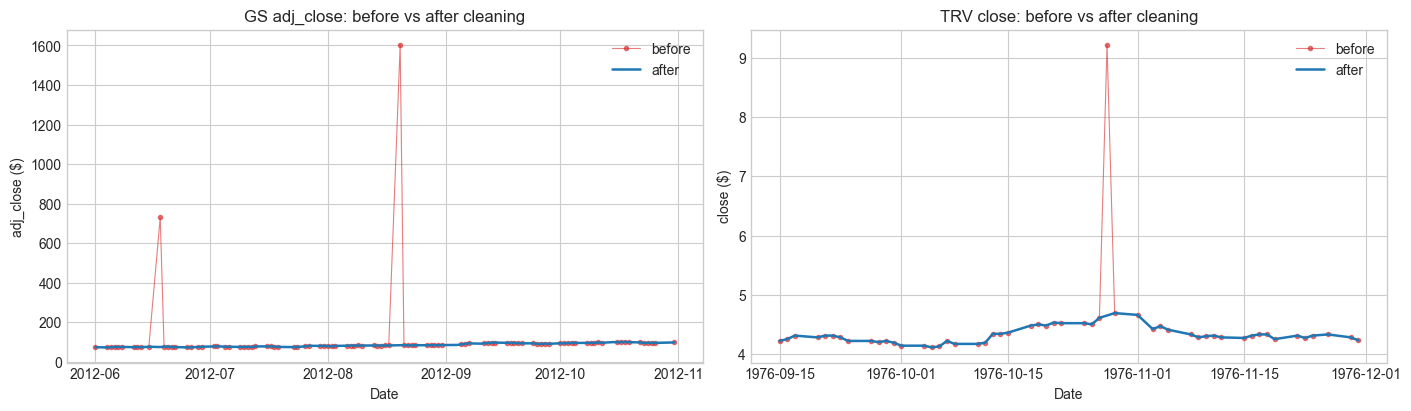

In [24]:
stats = pd.concat({'before (raw ohlc_hw)': raw[ALL_PRICES + ['volume']].describe().T[['count', 'mean', 'min', 'max']],
                   'after (ohlc_hw_cleaned)': cleaned[ALL_PRICES + ['volume']].describe().T[['count', 'mean', 'min', 'max']]}, axis=1)
display(stats.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4), layout='constrained')
for ax, (ticker, start, end) in zip(axes, [('GS', '2012-06-01', '2012-10-31'), ('TRV', '1976-09-15', '1976-11-30')]):
    before = checked[(checked['ticker'] == ticker) & checked['ts'].between(start, end)].sort_values('ts')
    after = cleaned[(cleaned['ticker'] == ticker) & cleaned['ts'].between(start, end)]
    col = 'adj_close' if ticker == 'GS' else 'close'
    ax.plot(before['ts'], before[col], color='#d62728', alpha=0.6, marker='.', lw=0.8, label='before')
    ax.plot(after['ts'], after[col], color='#1f77b4', lw=1.8, label='after')
    ax.set(title=f'{ticker} {col}: before vs after cleaning', xlabel='Date', ylabel=f'{col} ($)')
    ax.legend()
    ax.grid(True)
plt.show()

Left: corrupted `adj_close` values (red spikes, 4–24× too high) are replaced by `raw close × trusted factor`. Right: the TRV one-day doubling is replaced by the interpolated value.

### Save to the database
`ts` is stored as ISO `YYYY-MM-DD` text, so the report's `ts >= ? AND ts <= ?` SQL filters compare correctly. The tables written are `ohlc_hw_cleaned` (with all flags), `ohlc_hw_quarantine` (rows with reasons), `ohlc_hw_quality_report`, and `ohlc_hw_ticker_audit` (raw label → normalized ticker).

In [25]:
def to_sql_frame(df: pd.DataFrame, date_cols=('ts', 'issue_date')) -> pd.DataFrame:
    # Convert datetime columns to ISO date strings for SQLite.
    out = df.copy()
    for col in date_cols:
        if col in out:
            out[col] = pd.to_datetime(out[col]).dt.strftime('%Y-%m-%d')
    return out


with closing(sqlite3.connect(DB_PATH)) as conn, conn:   # inner `conn` context commits the transaction
    to_sql_frame(cleaned).to_sql(CLEAN_TABLE, conn, if_exists='replace', index=False)
    conn.execute(f'CREATE UNIQUE INDEX idx_{CLEAN_TABLE}_key ON {CLEAN_TABLE}(ticker, ts)')
    # Quarantined and removed rows share one table; removed rows carry a 'REMOVED:' reason prefix.
    set_aside = [quarantine] + ([removed.assign(reason='REMOVED: ' + removed['reason'])] if len(removed) else [])
    to_sql_frame(pd.concat(set_aside, ignore_index=True)).to_sql(QUARANTINE_TABLE, conn, if_exists='replace', index=False)
    to_sql_frame(quality_report).to_sql(REPORT_TABLE, conn, if_exists='replace', index=False)
    label_audit.to_sql(LABEL_AUDIT_TABLE, conn, if_exists='replace', index=False)

# Read back and verify what was written.
saved = load_table(CLEAN_TABLE)
assert len(saved) == len(cleaned)
assert saved['ts'].str.fullmatch(r'\d{4}-\d{2}-\d{2}').all()
assert validate_clean(saved.assign(ts=pd.to_datetime(saved['ts'])))['passed'].all()
assert table_fingerprint(load_table(RAW_TABLE)) == raw_fingerprint, 'Raw table must stay unchanged'
print(f"Saved {len(saved):,} rows to {CLEAN_TABLE}; raw table {RAW_TABLE} unchanged.")
with closing(sqlite3.connect(DB_PATH.resolve().as_uri() + '?mode=ro', uri=True)) as conn:
    display(pd.read_sql_query(f'SELECT ticker, MIN(ts) AS first, MAX(ts) AS last, COUNT(*) AS rows '
                              f'FROM {CLEAN_TABLE} GROUP BY ticker ORDER BY ticker LIMIT 5', conn))

Saved 368,246 rows to ohlc_hw_cleaned; raw table ohlc_hw unchanged.


,ticker,first,last,rows
0,AAPL,1980-12-12,2024-10-18,11050
1,AMGN,1983-06-17,2024-10-18,10421
2,AMZN,1997-05-15,2024-12-06,6937
3,AXP,1972-04-03,2024-10-18,13252
4,BA,1962-01-02,2024-10-18,15784


## Summary

* **Tickers:** 150 HTML-decorated labels → 30 symbols, audited in `ohlc_hw_ticker_audit`.
* **Duplicates:** 29,460 exact duplicates collapsed. No conflicting keys.
* **Missing data:** only `adj_close` (18,374 cells). Zero missing trading days against the per-ticker reference calendar.
* **Adjusted close:** ~10.4k corrupted values (4–24× too high) plus the missing values are rebuilt as `validated close × trusted factor` from `ohlc`. All retained rows now satisfy the backward-adjustment convention.
* **Impossible prices:** 5 first-day `open = 0` rows are quarantined because there is no earlier price to fill from. No high/low violations exist in the data. The repair logic is demonstrated on injected rows.
* **Outliers:** three TRV one-day "doubling" errors are confirmed by four independent pieces of evidence and interpolated. All other 3σ days are kept and flagged with a category.
* **Accounting:** every raw row is either retained, collapsed as an exact duplicate, removed, or quarantined. Repair flags are saved with the cleaned data.